# Tugas Machine Learning: Support Vector Machine dengan Scikit-learn

- Nama : Argreisto Daniel Krismiawan
- NIM : 241011400910
- Mata kuliah : Machine Learning

## Daftar isi

1. Latihan SKLearn SVM untuk Klasifikasi (dataset `diabetes.csv`)
2. Latihan SKLearn SVR (dataset `Salary_Data.csv`)
3. Latihan SVM (Kernel Linear): perhitungan manual dan SKLearn
4. Kesimpulan Umum dan Daftar Referensi

## Cara membaca notebook ini

Setiap latihan diawali kotak "Referensi materi" yang menunjukkan materi acuannya. Bagian utama di tiap latihan mengikuti materi, sedangkan bagian yang judulnya diawali "Tambahan:" adalah eksplorasi tambahan dariku (evaluasi lebih lengkap, perbandingan kernel, cross validation, grid search, dan lain-lain) supaya hasilnya bisa dibahas lebih dalam.

Dua file csv (`diabetes.csv` dan `Salary_Data.csv`) ada di folder `data/` (boleh juga ditaruh sejajar dengan notebook ini). Kalau dijalankan di Google Colab, nanti akan muncul tombol upload otomatis.

## Persiapan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     GridSearchCV, StratifiedKFold)
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, SVR
from sklearn import svm
from sklearn.metrics import (confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, RepeatedKFold
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, RocCurveDisplay)

def cari_file(nama):
    # cek dulu di folder sekarang dan di folder data/, kalau gak ada dan lagi di Colab baru minta upload
    for folder in ['.', 'data']:
        path = os.path.join(folder, nama)
        if os.path.exists(path):
            return path
    try:
        from google.colab import files
        print(f"{nama} belum ada, silakan upload filenya")
        files.upload()
        return nama
    except ImportError:
        raise FileNotFoundError(f"{nama} tidak ditemukan, taruh di folder data/ atau di folder yang sama dengan notebook ini")

# Latihan SKLearn SVM untuk Klasifikasi

> Referensi materi: Latihan SKLearn SVM untuk Klasifikasi. Dataset: Pima Indian Diabetes yang dikumpulkan oleh National Institute of Diabetes and Digestive and Kidney Diseases.

Tujuan: membuat model klasifikasi yang memprediksi apakah seorang pasien positif diabetes (1) atau tidak (0). Dataset berisi 768 pasien perempuan keturunan suku Indian Pima, dengan 8 atribut dan 1 kolom label (`Outcome`).

Tahapannya: ubah data ke dataframe, bagi dataset, standarisasi, buat dan latih model, lalu evaluasi.

## Membaca data

In [2]:
df = pd.read_csv(cari_file('diabetes.csv'))
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Dari `info()` terlihat ada 768 baris dan 9 kolom, semua `non-null` dan tipenya numerik (int64 dan float64). Jadi secara tampilan tidak ada missing value dan tidak ada kolom non numerik, data bisa langsung dipakai. (Tapi nanti di bagian tambahan saya cek lagi, soalnya ada hal yang janggal di nilai-nilainya.)

## Tambahan: Eksplorasi data

In [4]:
print("bentuk data:", df.shape)
df.describe().T

bentuk data: (768, 9)


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Dari `describe()` terlihat skala antar kolom beda jauh. `Insulin` maksimalnya 846, `Glucose` sampai 199, sedangkan `DiabetesPedigreeFunction` cuma sekitar 0.08 sampai 2.42. Ini alasan kenapa nanti perlu standarisasi. Selain itu, nilai minimum `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` dan `BMI` adalah 0, padahal secara medis tidak mungkin orang hidup dengan tekanan darah atau BMI 0.

Outcome
0    500
1    268
Name: count, dtype: int64

Outcome
0    65.1
1    34.9
Name: count, dtype: float64


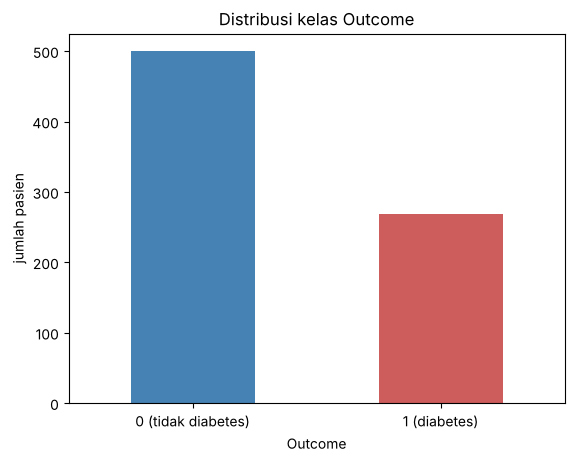

In [5]:
# distribusi kelas
jumlah = df['Outcome'].value_counts()
print(jumlah)
print()
print((jumlah / len(df) * 100).round(1))

jumlah.sort_index().plot(kind='bar', color=['steelblue', 'indianred'])
plt.xticks([0, 1], ['0 (tidak diabetes)', '1 (diabetes)'], rotation=0)
plt.ylabel('jumlah pasien')
plt.title('Distribusi kelas Outcome')
plt.show()

In [6]:
# cek nilai 0 yang mencurigakan
kolom_cek = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print((df[kolom_cek] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


Kelas tidak seimbang: kelas 0 ada 500 (65,1%) dan kelas 1 ada 268 (34,9%). Artinya model yang cuma menebak "tidak diabetes" terus sudah bisa dapat akurasi sekitar 65%. Jadi nanti akurasi model harus dibandingkan dengan angka ini, bukan dengan 50%.

Untuk nilai 0, hampir separuh baris `Insulin` (374) dan hampir sepertiga `SkinThickness` (227) bernilai 0. Kemungkinan besar ini sebenarnya missing value yang diisi 0 waktu pengumpulan data. Di materi hal ini tidak ditangani, jadi untuk bagian utama saya ikuti materi dulu, lalu dampaknya saya coba di bagian tambahan.

## Memisahkan atribut dan label, lalu standarisasi

In [7]:
# memisahkan atribut dan label
X = df[df.columns[:8]]
y = df['Outcome']
print(X.shape, y.shape)

(768, 8) (768,)


In [8]:
# standarisasi (mean 0, standar deviasi 1)
scaler = StandardScaler()
scaler.fit(X)
X_scaled = scaler.transform(X)

# cek hasilnya
pd.DataFrame(X_scaled, columns=X.columns).describe().loc[['mean', 'std']].round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
mean,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Setelah standarisasi, rata-rata semua kolom jadi 0 dan standar deviasinya 1, jadi skalanya sudah sama.

## Membagi data latih dan data uji

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.33, random_state=42)

print("data latih:", X_train.shape[0], "| data uji:", X_test.shape[0])

data latih: 514 | data uji: 254


## Membuat dan melatih model SVC

In [10]:
clf = SVC()
clf.fit(X_train, y_train)
print(clf)

SVC()


## Evaluasi model

In [11]:
# skor akurasi pada data uji (sesuai materi)
clf.score(X_test, y_test)

0.7559055118110236

Akurasinya sekitar 0,756 atau 75,6%. Angka ini cocok dengan hasil di materi.

## Tambahan: Evaluasi yang lebih lengkap

In [12]:
y_pred = clf.predict(X_test)

print("akurasi data latih :", round(clf.score(X_train, y_train), 4))
print("akurasi data uji   :", round(clf.score(X_test, y_test), 4))
print("akurasi kalau selalu menebak kelas 0:", round((y_test == 0).mean(), 4))
print()
print(classification_report(y_test, y_pred, target_names=['tidak diabetes', 'diabetes']))

akurasi data latih : 0.8366
akurasi data uji   : 0.7559
akurasi kalau selalu menebak kelas 0: 0.6614

                precision    recall  f1-score   support

tidak diabetes       0.80      0.85      0.82       168
      diabetes       0.66      0.58      0.62        86

      accuracy                           0.76       254
     macro avg       0.73      0.71      0.72       254
  weighted avg       0.75      0.76      0.75       254



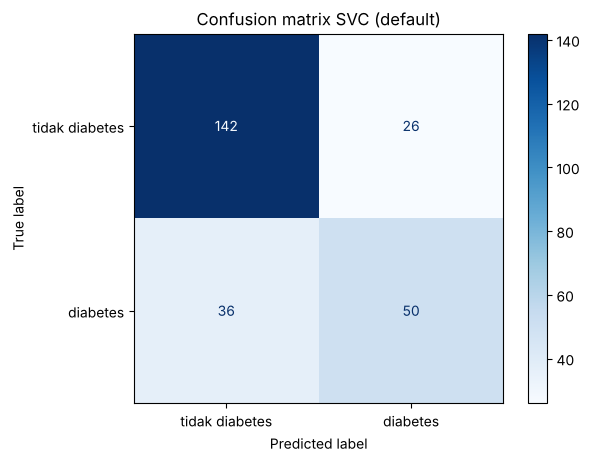

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['tidak diabetes', 'diabetes'], cmap='Blues')
plt.title('Confusion matrix SVC (default)')
plt.show()

Dari hasil di atas, akurasi data latih 83,7% sedangkan data uji 75,6%. Selisihnya sekitar 8 poin, jadi ada sedikit tanda overfitting tapi belum parah. Akurasi 75,6% memang di atas tebakan "selalu kelas 0" (66,1%), tapi bedanya cuma sekitar 10 poin.

Dari classification report, model jauh lebih jago mengenali pasien tidak diabetes (recall 0,85) daripada pasien diabetes (recall 0,58). Artinya sekitar 4 dari 10 pasien diabetes di data uji tidak terdeteksi (false negative). Untuk kasus medis ini kurang bagus, karena pasien sakit yang lolos lebih berbahaya daripada salah alarm. Jadi akurasi saja belum cukup untuk menilai model ini.

## Tambahan: Pengaruh standarisasi dan masalah data leakage

Di materi standarisasi dilakukan pada seluruh data sebelum dibagi. Secara teori ini kurang tepat karena rata-rata dan standar deviasi dihitung memakai data uji juga (data leakage). Cara yang lebih benar adalah `fit` scaler hanya pada data latih, dan ini mudah dilakukan dengan `Pipeline`. Sekalian saya bandingkan dengan model tanpa standarisasi sama sekali.

In [14]:
# bagi data mentah dulu
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

# 1) tanpa standarisasi
tanpa = SVC().fit(Xr_train, yr_train)

# 2) standarisasi di dalam pipeline (scaler hanya belajar dari data latih)
pipe = make_pipeline(StandardScaler(), SVC()).fit(Xr_train, yr_train)

print("tanpa standarisasi         :", round(tanpa.score(Xr_test, yr_test), 4))
print("standarisasi (versi materi):", round(clf.score(X_test, y_test), 4))
print("standarisasi via pipeline  :", round(pipe.score(Xr_test, yr_test), 4))

tanpa standarisasi         : 0.7441
standarisasi (versi materi): 0.7559
standarisasi via pipeline  : 0.752


Tanpa standarisasi akurasinya 74,4%, dengan standarisasi 75,6% (versi materi) dan 75,2% (pipeline). Jadi standarisasi membantu sedikit walaupun di dataset ini tidak besar. Selisih versi materi dan pipeline hanya 1 data uji (0,4%), jadi dampak leakage di sini hampir tidak terasa. Meski begitu, untuk praktik yang benar lebih baik pakai pipeline.

## Tambahan: Membandingkan kernel dengan cross validation

Akurasi dari satu kali split bisa kebetulan bagus atau jelek, jadi saya coba pakai 5-fold cross validation (stratified supaya proporsi kelas terjaga) untuk membandingkan 4 kernel bawaan SVC.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

hasil_kernel = []
for k in ['linear', 'poly', 'rbf', 'sigmoid']:
    model = make_pipeline(StandardScaler(), SVC(kernel=k))
    skor = cross_val_score(model, X, y, cv=cv)
    hasil_kernel.append([k, skor.mean(), skor.std()])

tabel_kernel = pd.DataFrame(hasil_kernel, columns=['kernel', 'rata-rata akurasi', 'std'])
tabel_kernel.round(4)

,kernel,rata-rata akurasi,std
0,linear,0.7708,0.0157
1,poly,0.7344,0.0229
2,rbf,0.7617,0.0173
3,sigmoid,0.7174,0.0362


Hasil CV: kernel linear paling tinggi (sekitar 77,1%), lalu rbf (76,2%), poly (73,4%), dan sigmoid paling rendah dan paling tidak stabil (71,7% dengan std 0,036). Selisih linear dan rbf kecil dan masih dalam kisaran standar deviasi (sekitar 1,6%), jadi keduanya bisa dianggap setara. Ini menunjukkan pola data diabetes ini sebagian besar sudah bisa dipisahkan secara linear, kernel yang lebih rumit tidak banyak menolong.

## Tambahan: Menangani nilai 0 yang janggal

Nilai 0 pada `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, dan `BMI` saya ganti menjadi NaN lalu diisi dengan median kolom (`SimpleImputer`). Imputasi ditaruh di dalam pipeline supaya median dihitung hanya dari data latih tiap fold.

In [16]:
X_nan = X.copy()
X_nan[kolom_cek] = X_nan[kolom_cek].replace(0, np.nan)
print(X_nan.isna().sum())

pipe_imp = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), SVC())
pipe_asli = make_pipeline(StandardScaler(), SVC())

skor_asli = cross_val_score(pipe_asli, X, y, cv=cv)
skor_imp = cross_val_score(pipe_imp, X_nan, y, cv=cv)

print()
print("CV tanpa penanganan nilai 0 :", round(skor_asli.mean(), 4))
print("CV dengan imputasi median   :", round(skor_imp.mean(), 4))

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64

CV tanpa penanganan nilai 0 : 0.7617
CV dengan imputasi median   : 0.7539


Hasilnya malah turun sedikit: 76,2% tanpa penanganan jadi 75,4% dengan imputasi median. Selisihnya kecil (masih di bawah standar deviasi antar fold), jadi bisa dibilang tidak berpengaruh signifikan. Kemungkinan karena median kurang cocok untuk `Insulin` yang hampir separuh datanya hilang, atau nilai 0 itu sendiri sudah membawa sedikit informasi (misalnya pasien memang tidak dites insulin). Walaupun tidak menaikkan akurasi, secara prinsip penanganan ini tetap masuk akal, tapi hasil utama latihan ini tetap pakai versi materi.

## Tambahan: Grid search untuk C dan gamma

`SVC()` default memakai `C=1` dan `gamma='scale'`. Saya coba cari kombinasi C dan gamma yang lebih baik dengan `GridSearchCV` (cross validation 5 fold pada data latih saja), lalu hasil terbaiknya diuji ke data uji.

In [17]:
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': [0.001, 0.01, 0.1, 1],
}

gs = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                  param_grid, cv=5, scoring='accuracy')
gs.fit(Xr_train, yr_train)

print("parameter terbaik   :", gs.best_params_)
print("akurasi CV terbaik  :", round(gs.best_score_, 4))
print("akurasi data uji    :", round(gs.score(Xr_test, yr_test), 4))

parameter terbaik   : {'svc__C': 10, 'svc__gamma': 0.001}
akurasi CV terbaik  : 0.7782
akurasi data uji    : 0.752


In [18]:
# tabel akurasi CV untuk semua kombinasi
hasil_gs = pd.DataFrame(gs.cv_results_)
tabel_gs = hasil_gs.pivot_table(index='param_svc__C', columns='param_svc__gamma',
                                values='mean_test_score')
tabel_gs.round(3)

param_svc__gamma,0.001,0.010,0.100,1.000
param_svc__C,,,,
0.1,0.646,0.646,0.716,0.646
1.0,0.644,0.776,0.759,0.677
10.0,0.778,0.765,0.751,0.689
100.0,0.766,0.751,0.718,0.689


Kombinasi terbaik adalah C=10 dan gamma=0,001 dengan akurasi CV 77,8%, tetapi akurasi di data uji 75,2%, sama saja dengan SVC default yang pakai pipeline. Jadi grid search tidak memberi peningkatan nyata di data uji.

Dari tabel terlihat pola: C kecil (0,1) membuat model underfitting (umumnya sekitar 64-65%, hampir sama dengan menebak kelas 0 terus), dan gamma besar (1) membuat overfitting (turun ke sekitar 65-69%). Daerah yang bagus ada di tengah-tengah. Gamma terbaik sangat kecil (0,001), artinya batas keputusannya hampir linear, konsisten dengan hasil kernel linear yang bagus tadi.

## Tambahan: Apakah 75,6% itu stabil? (uji dengan banyak random_state)

Angka 75,6% keluar dari satu kali pembagian data (`random_state=42`). Supaya tahu seberapa stabil, saya ulang pembagian data latih dan uji dengan 30 random_state yang berbeda (pakai pipeline dan `stratify=y` supaya proporsi kelas terjaga), lalu lihat rata-rata dan sebarannya.

rata-rata akurasi : 0.7564
std               : 0.0198
min / max         : 0.7126 / 0.7835


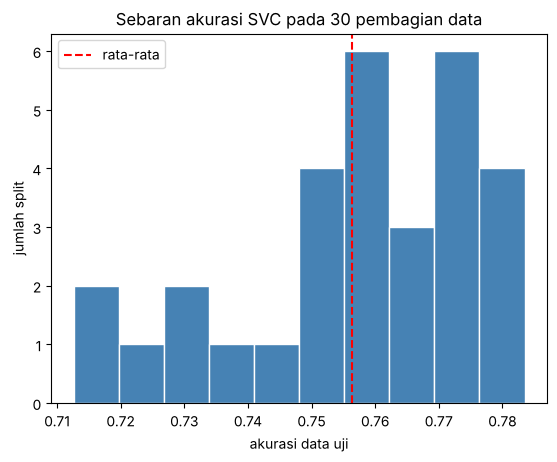

In [19]:
akurasi_split = []
for seed in range(30):
    a_tr, a_te, b_tr, b_te = train_test_split(X, y, test_size=0.33, random_state=seed, stratify=y)
    m = make_pipeline(StandardScaler(), SVC()).fit(a_tr, b_tr)
    akurasi_split.append(m.score(a_te, b_te))
akurasi_split = np.array(akurasi_split)

print("rata-rata akurasi :", round(akurasi_split.mean(), 4))
print("std               :", round(akurasi_split.std(), 4))
print("min / max         :", round(akurasi_split.min(), 4), "/", round(akurasi_split.max(), 4))

plt.hist(akurasi_split, bins=10, color='steelblue', edgecolor='white')
plt.axvline(akurasi_split.mean(), color='red', linestyle='--', label='rata-rata')
plt.xlabel('akurasi data uji')
plt.ylabel('jumlah split')
plt.title('Sebaran akurasi SVC pada 30 pembagian data')
plt.legend()
plt.show()

Rata-rata akurasi dari 30 pembagian data adalah 75,6% dengan standar deviasi sekitar 2% (terendah 71,3%, tertinggi 78,4%). Jadi angka 75,6% di materi kebetulan hampir tepat di rata-ratanya, tapi hasil satu kali split bisa meleset sampai sekitar 4 poin. Artinya perbedaan kecil antar model (misalnya selisih 0,4% antara versi materi dan pipeline) tidak bisa dianggap bermakna.

## Tambahan: Menangani kelas tidak seimbang dengan class_weight dan kurva ROC

Tadi recall untuk kelas diabetes cuma 0,58. SVC punya parameter `class_weight='balanced'` yang membuat kesalahan pada kelas minoritas dihukum lebih berat. Saya bandingkan dengan SVC biasa pada data uji yang sama.

In [20]:
model_biasa = make_pipeline(StandardScaler(), SVC()).fit(Xr_train, yr_train)
model_seimbang = make_pipeline(StandardScaler(), SVC(class_weight='balanced')).fit(Xr_train, yr_train)

baris = []
for nama, m in [('SVC biasa', model_biasa), ('SVC class_weight=balanced', model_seimbang)]:
    p = m.predict(Xr_test)
    baris.append([nama,
                  m.score(Xr_test, yr_test),
                  precision_score(yr_test, p),
                  recall_score(yr_test, p),
                  f1_score(yr_test, p),
                  roc_auc_score(yr_test, m.decision_function(Xr_test))])

pd.DataFrame(baris, columns=['model', 'akurasi', 'precision (diabetes)', 'recall (diabetes)',
                             'f1 (diabetes)', 'ROC AUC']).round(3)

,model,akurasi,precision (diabetes),recall (diabetes),f1 (diabetes),ROC AUC
0,SVC biasa,0.752,0.653,0.570,0.609,0.802
1,SVC class_weight=balanced,0.717,0.566,0.698,0.625,0.803


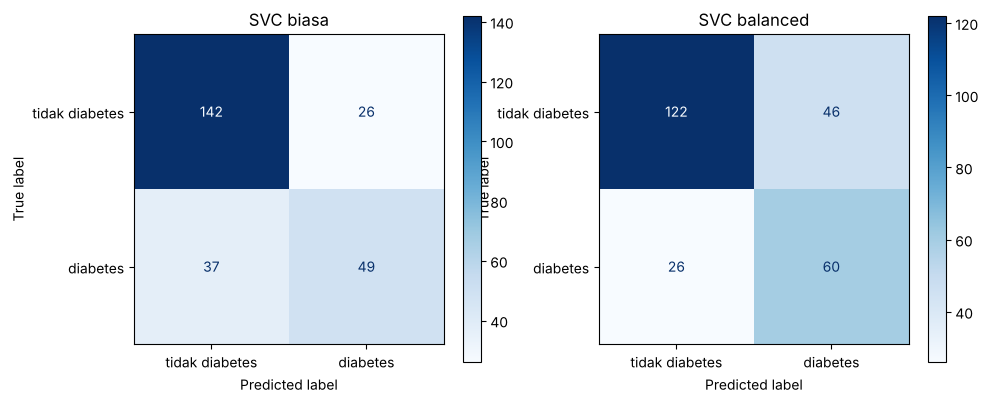

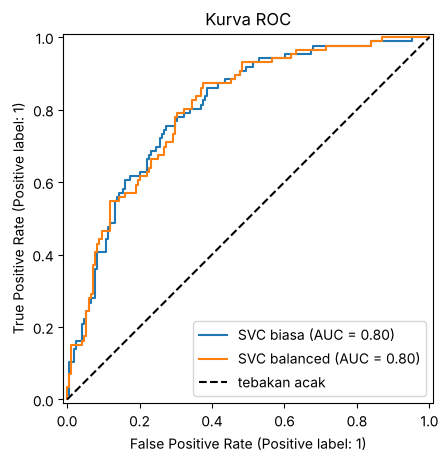

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (nama, m) in zip(ax, [('SVC biasa', model_biasa), ('SVC balanced', model_seimbang)]):
    ConfusionMatrixDisplay.from_predictions(yr_test, m.predict(Xr_test),
        display_labels=['tidak diabetes', 'diabetes'], cmap='Blues', ax=a)
    a.set_title(nama)
plt.show()

RocCurveDisplay.from_estimator(model_biasa, Xr_test, yr_test, name='SVC biasa')
ax_roc = plt.gca()
RocCurveDisplay.from_estimator(model_seimbang, Xr_test, yr_test, name='SVC balanced', ax=ax_roc)
ax_roc.plot([0, 1], [0, 1], 'k--', label='tebakan acak')
ax_roc.legend()
plt.title('Kurva ROC')
plt.show()

Dengan `class_weight='balanced'`, recall untuk kelas diabetes naik dari 0,57 menjadi 0,70, artinya lebih banyak pasien diabetes yang terdeteksi. Harganya precision turun (0,65 jadi 0,57) dan akurasi turun dari 75,2% ke 71,7%, karena lebih banyak pasien sehat yang diprediksi diabetes. ROC AUC hampir sama (sekitar 0,80), artinya kemampuan model memisahkan kedua kelas sebenarnya tidak berubah, yang bergeser hanya titik keputusannya. Untuk skrining penyakit, recall yang lebih tinggi biasanya lebih diutamakan, jadi versi balanced lebih masuk akal walaupun akurasinya turun.

## Tambahan: Dibandingkan dengan model klasifikasi lain

Supaya hasil SVM punya pembanding, saya coba beberapa model lain dengan cross validation 5 fold yang sama (semuanya lewat pipeline dengan standarisasi).

In [22]:
model_lain = {
    'SVC rbf': make_pipeline(StandardScaler(), SVC()),
    'SVC linear': make_pipeline(StandardScaler(), SVC(kernel='linear')),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'KNN (k=15)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'Random Forest': make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, random_state=42)),
}

baris = []
for nama, m in model_lain.items():
    skor = cross_val_score(m, X, y, cv=cv)
    baris.append([nama, skor.mean(), skor.std()])

pd.DataFrame(baris, columns=['model', 'rata-rata akurasi CV', 'std']).sort_values(
    'rata-rata akurasi CV', ascending=False).round(4).reset_index(drop=True)

,model,rata-rata akurasi CV,std
0,Logistic Regression,0.7747,0.0147
1,SVC linear,0.7708,0.0157
2,Random Forest,0.7630,0.0155
3,SVC rbf,0.7617,0.0173
4,KNN (k=15),0.7487,0.0169


Semua model ada di kisaran 75-77%: Logistic Regression 77,5%, SVC linear 77,1%, Random Forest 76,3%, SVC rbf 76,2%, dan KNN 74,9%. Selisih antar model masih di dalam standar deviasi (sekitar 1,5%), jadi SVM tidak lebih baik atau lebih buruk secara berarti dari model lain. Logistic Regression yang paling sederhana justru paling tinggi, mendukung dugaan bahwa pola data ini hampir linear dan batas performanya ada di fitur yang tersedia.

## Kesimpulan Latihan SKLearn SVM untuk Klasifikasi

- SVC dengan pengaturan default dan standarisasi mencapai akurasi 75,6% di data uji, sesuai dengan hasil di materi, dan lebih tinggi dari baseline (selalu menebak "tidak diabetes" = 66,1%).
- Hasil satu kali split tidak stabil: dari 30 pembagian data akurasinya berkisar 71-78% (rata-rata 75,6%, std sekitar 2%). Jadi selisih kecil antar model tidak bisa dianggap bermakna.
- Recall kelas diabetes hanya sekitar 0,57-0,58, jadi model sering melewatkan pasien diabetes. `class_weight='balanced'` menaikkannya ke 0,70, dengan akurasi turun ke 71,7%.
- Standarisasi perlu karena skala kolom beda jauh; efeknya di dataset ini kecil tapi positif. Cara yang benar adalah lewat pipeline supaya tidak ada data leakage.
- Kernel linear dan rbf hasilnya hampir sama (sekitar 76-77% di cross validation), sigmoid paling jelek. Model lain (Logistic Regression, KNN, Random Forest) juga setara di kisaran 75-77%.
- Grid search dan imputasi nilai 0 tidak menaikkan akurasi data uji secara berarti. Batas performa dengan 8 fitur ini kelihatannya memang sekitar 75-78%.

# Latihan SKLearn SVR

> Referensi materi: Latihan SKLearn SVR. Dataset: Salary_Data (lama kerja dan gaji).

Tujuan: menerapkan Support Vector Regression untuk memprediksi gaji (`Salary`) berdasarkan lama pengalaman kerja (`YearsExperience`).

Tahapannya: ubah data jadi dataframe, pisahkan atribut dan label, latih model SVR, lalu buat plot dari model.

## Membaca data

In [23]:
data = pd.read_csv(cari_file('Salary_Data.csv'))
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [24]:
data.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


Datanya cuma 30 baris dan 2 kolom, keduanya float64 dan tidak ada missing value, sama seperti yang disebutkan di materi.

## Tambahan: Eksplorasi data

       YearsExperience     Salary
count            30.00      30.00
mean              5.31   76003.00
std               2.84   27414.43
min               1.10   37731.00
25%               3.20   56720.75
50%               4.70   65237.00
75%               7.70  100544.75
max              10.50  122391.00

korelasi: 0.9782


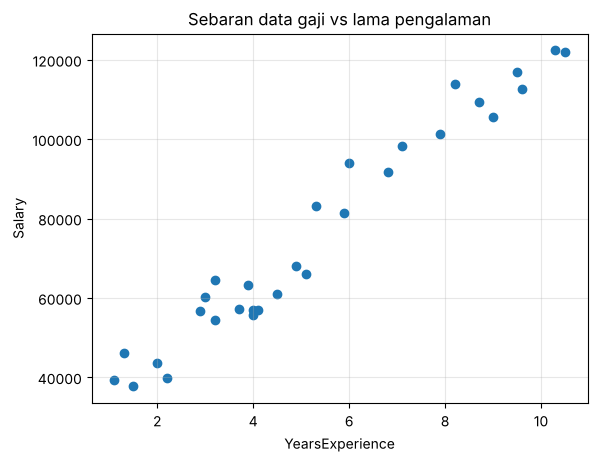

In [25]:
print(data.describe().round(2))
print()
print("korelasi:", round(data['YearsExperience'].corr(data['Salary']), 4))

plt.scatter(data['YearsExperience'], data['Salary'])
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('Sebaran data gaji vs lama pengalaman')
plt.grid(alpha=0.3)
plt.show()

Korelasi antara pengalaman dan gaji sangat tinggi (sekitar 0,98) dan polanya hampir lurus: makin lama pengalaman makin besar gaji. Skala `Salary` juga jauh lebih besar dari `YearsExperience` (puluhan ribu sampai seratusan ribu, sedangkan pengalaman hanya 1 sampai 10,5 tahun). Dua hal ini penting untuk dibahas nanti waktu melihat kenapa model awalnya kurang bagus.

## Memisahkan atribut dan label

In [26]:
X = data['YearsExperience']
y = data['Salary']

# atribut cuma satu kolom, jadi bentuknya harus diubah jadi 2 dimensi
X = np.array(X)
X = X[:, np.newaxis]

print("bentuk X:", X.shape)
print("bentuk y:", y.shape)

bentuk X: (30, 1)
bentuk y: (30,)


Sklearn meminta X berbentuk 2 dimensi (jumlah sampel, jumlah atribut). Kalau X dibiarkan 1 dimensi akan muncul error, makanya dipakai `np.newaxis`.

## Melatih model SVR

In [27]:
model = SVR(C=1000, gamma=0.05, kernel='rbf')
model.fit(X, y)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.05
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


## Visualisasi model

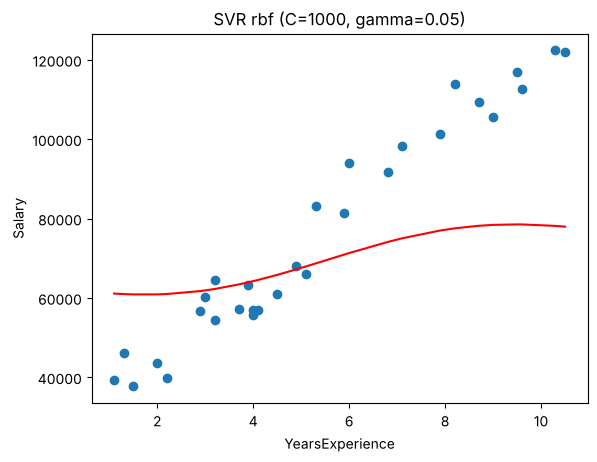

In [28]:
plt.scatter(X, y)
plt.plot(X, model.predict(X), color='red')
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('SVR rbf (C=1000, gamma=0.05)')
plt.show()

Sesuai yang dibilang di materi, garis model belum bisa mengikuti pola data. Garisnya terlalu landai: di pengalaman rendah prediksinya terlalu tinggi, dan di pengalaman tinggi prediksinya terlalu rendah.

## Tambahan: Mengukur performa dan mencari penyebab

In [29]:
pred = model.predict(X)
print("R2   :", round(r2_score(y, pred), 4))
print("MAE  :", round(mean_absolute_error(y, pred), 2))
print("RMSE :", round(np.sqrt(mean_squared_error(y, pred)), 2))

R2   : 0.351
MAE  : 17351.24
RMSE : 21713.92


R² cuma sekitar 0,35, artinya model baru menjelaskan sekitar 35% variasi gaji. Dugaan saya penyebabnya ada di parameter `C`. Pada SVR, `C` mengatur seberapa besar penalti untuk error, dan error di sini diukur dalam satuan gaji (puluhan ribu). Dengan `C=1000` penaltinya jadi terlalu kecil dibanding skala `y`, sehingga model "malas" mengikuti data dan lebih memilih fungsi yang halus dan datar. Saya buktikan dengan menaikkan nilai C.

In [30]:
baris = []
for C in [1e3, 1e4, 1e5, 1e6]:
    m = SVR(C=C, gamma=0.05, kernel='rbf').fit(X, y)
    baris.append([C, r2_score(y, m.predict(X))])

pd.DataFrame(baris, columns=['C', 'R2 (data latih)']).round(4)

,C,R2 (data latih)
0,1000.0,0.3510
1,10000.0,0.9525
2,100000.0,0.9618
3,1000000.0,0.9653


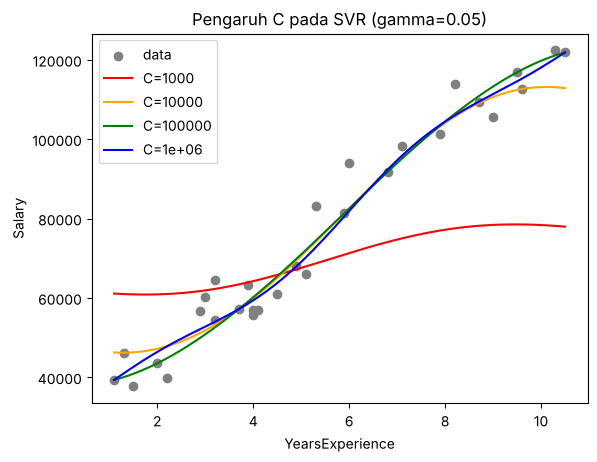

In [31]:
# bandingkan visual beberapa nilai C, gamma tetap 0.05
x_plot = np.linspace(X.min(), X.max(), 200)[:, np.newaxis]

plt.scatter(X, y, color='gray', label='data')
for C, warna in [(1e3, 'red'), (1e4, 'orange'), (1e5, 'green'), (1e6, 'blue')]:
    m = SVR(C=C, gamma=0.05, kernel='rbf').fit(X, y)
    plt.plot(x_plot, m.predict(x_plot), color=warna, label=f'C={C:g}')
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('Pengaruh C pada SVR (gamma=0.05)')
plt.legend()
plt.show()

Terbukti: makin besar `C`, garis makin dekat dengan data dan R² naik tajam. Jadi memang masalah utamanya adalah `C` yang terlalu kecil untuk skala gaji, bukan kernel atau datanya.

## Tambahan: Mencari parameter dengan grid search dan memakai data uji

Sampai sini semua evaluasi dilakukan di data latih, padahal seharusnya model diuji pada data yang belum pernah dilihat. Jadi data saya bagi 80% latih dan 20% uji. Karena data cuma 30 baris, uji-nya cuma 6 titik, jadi hasilnya perlu dibaca hati-hati. Parameter dicari dengan `GridSearchCV` (sesuai yang akan dipelajari di modul berikutnya).

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("data latih:", len(X_train), "| data uji:", len(X_test))

param_grid = {
    'kernel': ['rbf'],
    'C': [1e3, 1e4, 1e5, 1e6],
    'gamma': [0.001, 0.01, 0.05, 0.1, 0.5],
}
gs_svr = GridSearchCV(SVR(), param_grid, cv=5, scoring='r2')
gs_svr.fit(X_train, y_train)

print("parameter terbaik :", gs_svr.best_params_)
print("R2 CV terbaik     :", round(gs_svr.best_score_, 4))

data latih: 24 | data uji: 6
parameter terbaik : {'C': 100000.0, 'gamma': 0.5, 'kernel': 'rbf'}
R2 CV terbaik     : 0.9074


In [33]:
# bandingkan beberapa model di data uji
kandidat = {
    'SVR materi (C=1000, gamma=0.05)': SVR(C=1000, gamma=0.05, kernel='rbf'),
    'SVR hasil grid search': gs_svr.best_estimator_,
    'SVR kernel linear (C=1000)': SVR(C=1000, kernel='linear'),
    'Linear Regression (pembanding)': LinearRegression(),
}

baris = []
for nama, m in kandidat.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    baris.append([nama, r2_score(y_test, p),
                  mean_absolute_error(y_test, p),
                  np.sqrt(mean_squared_error(y_test, p))])

pd.DataFrame(baris, columns=['model', 'R2 uji', 'MAE uji', 'RMSE uji']).round(3)

,model,R2 uji,MAE uji,RMSE uji
0,"SVR materi (C=1000, gamma=0.05)",-0.124,17793.091,23960.727
1,SVR hasil grid search,0.875,6775.753,8002.150
2,SVR kernel linear (C=1000),0.908,6261.625,6873.439
3,Linear Regression (pembanding),0.902,6286.454,7059.044


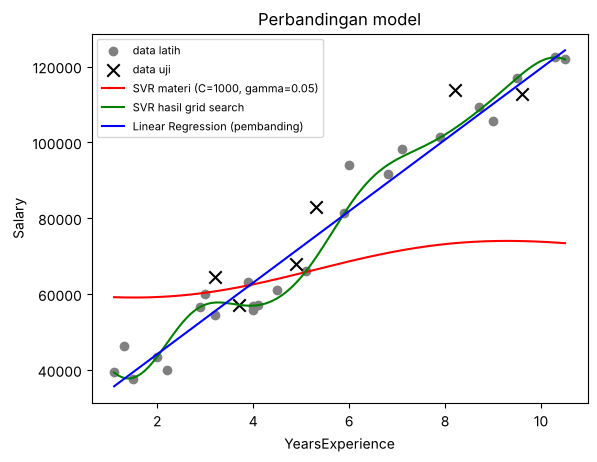

In [34]:
plt.scatter(X_train, y_train, color='gray', label='data latih')
plt.scatter(X_test, y_test, color='black', marker='x', s=80, label='data uji')
for nama, warna in [('SVR materi (C=1000, gamma=0.05)', 'red'),
                    ('SVR hasil grid search', 'green'),
                    ('Linear Regression (pembanding)', 'blue')]:
    plt.plot(x_plot, kandidat[nama].predict(x_plot), color=warna, label=nama)
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('Perbandingan model')
plt.legend(fontsize=8)
plt.show()

In [35]:
# contoh prediksi untuk pengalaman baru
model_akhir = SVR(**gs_svr.best_params_).fit(X, y)   # dilatih ulang dengan semua data
for tahun in [2, 5, 8, 12]:
    gaji = model_akhir.predict([[tahun]])[0]
    print(f"pengalaman {tahun:>2} tahun -> prediksi gaji sekitar {gaji:,.0f}")

pengalaman  2 tahun -> prediksi gaji sekitar 42,602
pengalaman  5 tahun -> prediksi gaji sekitar 69,847
pengalaman  8 tahun -> prediksi gaji sekitar 109,816
pengalaman 12 tahun -> prediksi gaji sekitar 90,591


Hasil di data uji: SVR dari materi punya R² negatif (-0,124), artinya lebih jelek daripada sekadar memprediksi rata-rata gaji. Setelah grid search (C=100000, gamma=0,5), R² naik jadi 0,875 dan rata-rata error (MAE) turun dari sekitar 17.800 menjadi 6.800. SVR kernel linear (0,908) dan Linear Regression (0,902) malah sedikit lebih bagus, wajar karena polanya hampir lurus (korelasi 0,98). Tapi data ujinya cuma 6 titik, jadi selisih 0,875 vs 0,908 tidak bisa dibilang signifikan.

Dari contoh prediksi, untuk 2, 5, dan 8 tahun hasilnya masuk akal. Tapi untuk 12 tahun (di luar rentang data yang cuma 1 sampai 10,5) prediksinya malah turun jadi sekitar 90 ribu, lebih rendah dari 8 tahun. Ini kelemahan kernel rbf: di luar rentang data, prediksinya cenderung kembali ke nilai tengah, jadi tidak cocok untuk ekstrapolasi. Untuk kasus seperti ini kernel linear lebih aman.

## Tambahan: Apakah masalahnya di skala gaji? (standarisasi target)

Tadi dugaannya `C=1000` terlalu kecil karena gaji bernilai puluhan ribu. Kalau dugaan itu benar, seharusnya model dengan parameter yang sama (C=1000, gamma=0,05) jadi bagus kalau gajinya diskalakan dulu. Saya coba pakai `TransformedTargetRegressor` yang menstandarisasi `y` saat latihan lalu mengembalikannya ke skala asli saat prediksi.

In [36]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

varian = {
    'materi (tanpa scaling)': SVR(C=1000, gamma=0.05),
    'y distandarisasi': TransformedTargetRegressor(
        regressor=SVR(C=1000, gamma=0.05), transformer=StandardScaler()),
    'X dan y distandarisasi': TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), SVR(C=1000, gamma=0.05)),
        transformer=StandardScaler()),
}

baris = []
for nama, m in varian.items():
    m.fit(X, y)
    r2_latih = r2_score(y, m.predict(X))
    r2_cv = cross_val_score(m, X, y, cv=kf, scoring='r2').mean()
    baris.append([nama, r2_latih, r2_cv])

pd.DataFrame(baris, columns=['varian', 'R2 data latih', 'R2 cross validation']).round(4)

,varian,R2 data latih,R2 cross validation
0,materi (tanpa scaling),0.3510,-0.0347
1,y distandarisasi,0.9681,0.9262
2,X dan y distandarisasi,0.9632,0.9117


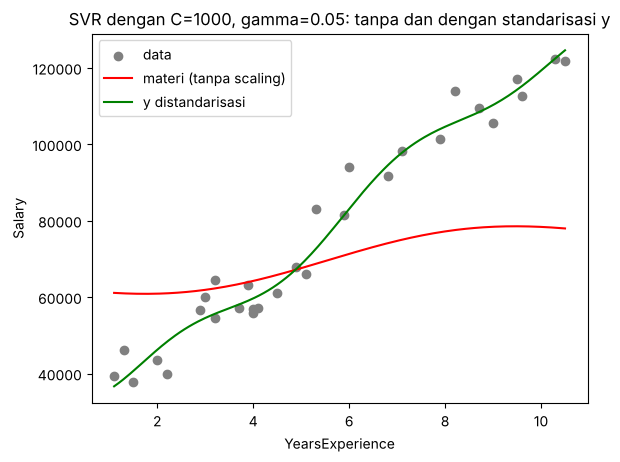

In [37]:
plt.scatter(X, y, color='gray', label='data')
for nama, warna in [('materi (tanpa scaling)', 'red'), ('y distandarisasi', 'green')]:
    plt.plot(x_plot, varian[nama].predict(x_plot), color=warna, label=nama)
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('SVR dengan C=1000, gamma=0.05: tanpa dan dengan standarisasi y')
plt.legend()
plt.show()

Dugaan terbukti. Dengan parameter yang persis sama (C=1000, gamma=0,05), cukup dengan menstandarisasi `y`, R² data latih naik dari 0,35 menjadi 0,97 dan R² cross validation dari -0,03 menjadi 0,93. Jadi masalah model di materi bukan di kernel atau datanya, tapi skala target yang tidak cocok dengan nilai C. Standarisasi `X` tambahan tidak banyak mengubah (R² cross validation 0,91), mungkin karena `X` sudah berskala kecil (1 sampai 10,5).

Catatan: R² cross validation model materi negatif (-0,03), artinya pada data yang belum dilihat, model itu tidak lebih baik daripada sekadar memprediksi rata-rata gaji.

## Tambahan: Pengaruh gamma

`gamma` mengatur seberapa lokal pengaruh tiap titik data pada kernel rbf. Dengan C dibuat besar (100000), saya bandingkan R² data latih dan R² cross validation untuk beberapa nilai gamma, untuk melihat kapan model underfitting dan kapan overfitting.

In [38]:
baris = []
for g in [0.0001, 0.001, 0.01, 0.05, 0.5, 5, 50]:
    m = SVR(C=1e5, gamma=g, kernel='rbf')
    m.fit(X, y)
    baris.append([g, r2_score(y, m.predict(X)),
                  cross_val_score(m, X, y, cv=kf, scoring='r2').mean()])

tabel_gamma = pd.DataFrame(baris, columns=['gamma', 'R2 data latih', 'R2 cross validation'])
tabel_gamma.round(4)

,gamma,R2 data latih,R2 cross validation
0,0.0001,0.1323,-0.2952
1,0.0010,0.9409,0.8546
2,0.0100,0.9628,0.9243
3,0.0500,0.9618,0.9041
4,0.5000,0.9759,0.9090
5,5.0000,0.9885,0.7992
6,50.0000,0.9953,0.1291


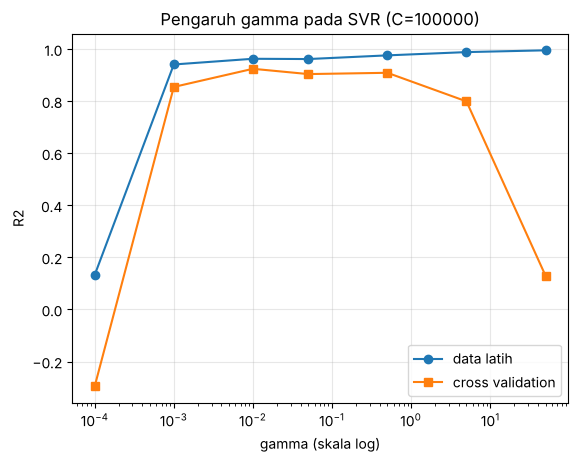

In [39]:
plt.semilogx(tabel_gamma['gamma'], tabel_gamma['R2 data latih'], 'o-', label='data latih')
plt.semilogx(tabel_gamma['gamma'], tabel_gamma['R2 cross validation'], 's-', label='cross validation')
plt.xlabel('gamma (skala log)')
plt.ylabel('R2')
plt.title('Pengaruh gamma pada SVR (C=100000)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Gamma terlalu kecil (0,0001) membuat model underfitting (R² latih 0,13 dan R² cross validation negatif). Rentang gamma 0,01 sampai 0,5 bagus (R² cross validation sekitar 0,90 sampai 0,92, tertinggi di gamma 0,01 sebesar 0,924). Makin besar gamma dari situ, R² latih terus naik (0,995 pada gamma 50) tapi R² cross validation jatuh (0,13 pada gamma 50), tanda overfitting karena model seperti menghafal titik-titik data. Jadi gamma 0,05 di materi sebenarnya sudah ada di daerah yang bagus, asal C-nya cukup besar.

## Tambahan: Perbandingan model dengan repeated cross validation

Data uji yang cuma 6 titik terlalu kecil untuk membandingkan model dengan adil. Jadi saya pakai repeated k-fold (5 fold diulang 10 kali dengan pembagian acak berbeda, total 50 evaluasi) pada seluruh data, dan melihat R² serta MAE.

In [40]:
rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)

model_bandingan = {
    'SVR materi (C=1000, gamma=0.05)': SVR(C=1000, gamma=0.05),
    'SVR hasil grid search': SVR(**gs_svr.best_params_),
    'SVR y distandarisasi (C=1000)': TransformedTargetRegressor(
        regressor=SVR(C=1000, gamma=0.05), transformer=StandardScaler()),
    'SVR kernel linear (C=1000)': SVR(C=1000, kernel='linear'),
    'Linear Regression': LinearRegression(),
}

baris = []
for nama, m in model_bandingan.items():
    r2 = cross_val_score(m, X, y, cv=rkf, scoring='r2')
    mae = -cross_val_score(m, X, y, cv=rkf, scoring='neg_mean_absolute_error')
    baris.append([nama, r2.mean(), r2.std(), mae.mean()])

pd.DataFrame(baris, columns=['model', 'R2 rata-rata', 'R2 std', 'MAE rata-rata']).round(3)

,model,R2 rata-rata,R2 std,MAE rata-rata
0,"SVR materi (C=1000, gamma=0.05)",-0.803,3.657,20210.031
1,SVR hasil grid search,0.884,0.167,5402.674
2,SVR y distandarisasi (C=1000),0.839,0.365,5382.103
3,SVR kernel linear (C=1000),0.841,0.462,5314.180
4,Linear Regression,0.860,0.377,4980.973


Dari 50 evaluasi: SVR hasil grid search punya R² rata-rata tertinggi (0,884), sedangkan Linear Regression punya MAE terkecil (sekitar 4.981). SVR dari materi paling jelek (R² rata-rata -0,80 dan MAE sekitar 20.200). Standar deviasi R² besar karena tiap fold hanya berisi 6 titik, jadi MAE lebih enak dibaca sebagai ukuran kesalahan dalam satuan gaji.

Catatan: parameter grid search dicari dari 24 data latih yang juga ikut dalam cross validation ini, jadi nilainya sedikit optimis. Kesimpulannya, selisih antara SVR yang sudah disetel, SVR dengan `y` distandarisasi, SVR linear, dan Linear Regression kecil. Yang jelas berbeda hanya model materi dengan pengaturan awalnya.

## Kesimpulan Latihan SKLearn SVR

- Model SVR dari materi (C=1000, gamma=0,05, kernel rbf) belum cocok dengan data: R² sekitar 0,35 di data latih dan negatif di data uji maupun cross validation.
- Penyebab utamanya `C` terlalu kecil dibanding skala gaji (puluhan sampai ratusan ribu). Buktinya, dengan parameter yang sama tapi `y` distandarisasi, R² cross validation naik dari -0,03 jadi 0,93. Menaikkan C ke 10.000 atau lebih juga membuat R² naik ke sekitar 0,95.
- Gamma yang bagus ada di rentang 0,01 sampai 0,5. Gamma terlalu kecil membuat underfitting dan gamma terlalu besar (5 ke atas) membuat overfitting.
- Grid search menemukan C=100000 dan gamma=0,5 dengan R² uji 0,875. Di repeated cross validation, SVR yang sudah disetel, SVR linear, dan Linear Regression hasilnya setara, karena hubungan pengalaman dan gaji memang hampir linear.
- Catatan: dataset hanya 30 baris sehingga hasil data uji (6 titik) mudah berubah kalau split-nya diganti, dan SVR rbf tidak bagus untuk memprediksi di luar rentang data.

# Latihan SVM (Kernel Linear)

> Referensi materi: Latihan SVM, berisi catatan perhitungan manual SVM kernel linear (contoh lama belajar dan lama tidur) dan implementasinya dengan SKLearn.

Tujuan: memahami cara kerja SVM kernel linear dengan menghitung manual hyperplane dan margin-nya, lalu membandingkannya dengan hasil `svm.SVC(kernel='linear')` dari sklearn.

Datanya 8 siswa dengan dua fitur: lama belajar (x1) dan lama tidur (x2), label +1 untuk lulus dan -1 untuk tidak lulus.

## Data

In [41]:
x1 = np.array([2, 1, 3, 1, 4, 2, 5, 2])   # Study Hours
x2 = np.array([8, 6, 7, 4, 6, 5, 7, 3])   # Sleep Hours
y = np.array([1, -1, 1, -1, 1, -1, 1, -1])   # Passed Exam

# X harus 2 dimensi, y 1 dimensi
X = np.column_stack((x1, x2))
print("X:", X.shape, "| y:", y.shape)

pd.DataFrame({'x1 (belajar)': x1, 'x2 (tidur)': x2, 'y': y})

X: (8, 2) | y: (8,)


,x1 (belajar),x2 (tidur),y
0,2,8,1
1,1,6,-1
2,3,7,1
3,1,4,-1
4,4,6,1
5,2,5,-1
6,5,7,1
7,2,3,-1


## Perhitungan manual

Persamaan hyperplane: w1·x1 + w2·x2 + b = 0, dengan margin di w·x + b = +1 untuk kelas lulus dan w·x + b = -1 untuk kelas tidak lulus.

Empat support vector yang dipilih (titik paling dekat dengan batas): (3,7) dan (4,6) untuk kelas +1, lalu (1,6) dan (2,5) untuk kelas -1. Langkah di catatan:

- Kurangkan dua persamaan di kelas yang sama: (4w1 + 6w2 + b) - (3w1 + 7w2 + b) = 0, jadi w1 - w2 = 0 atau w1 = w2.
- Substitusi w1 = w2: `10w1 + b = 1` dan `7w1 + b = -1`.
- Kurangkan: 3w1 = 2, jadi w1 = w2 = 2/3.
- Lalu b = 1 - 20/3 = -17/3.
- Garis batas: (2/3)x1 + (2/3)x2 - 17/3 = 0, atau x2 = -x1 + 8,5.

Supaya yakin, saya cek hitungan di atas dengan kode.

In [42]:
# cek: substitusi w1 = w2 = 2/3 dan b = -17/3 ke keempat support vector
w1_manual, w2_manual, b_manual = 2/3, 2/3, -17/3

sv_manual = [((3, 7), +1), ((4, 6), +1), ((1, 6), -1), ((2, 5), -1)]
for (a, b_), label in sv_manual:
    nilai = w1_manual * a + w2_manual * b_ + b_manual
    print(f"titik ({a},{b_}) kelas {label:+d} -> w.x + b = {nilai:.4f}")

titik (3,7) kelas +1 -> w.x + b = 1.0000
titik (4,6) kelas +1 -> w.x + b = 1.0000
titik (1,6) kelas -1 -> w.x + b = -1.0000
titik (2,5) kelas -1 -> w.x + b = -1.0000


In [43]:
# cek lagi dengan menyelesaikan sistem persamaan pakai numpy
# 3w1 + 7w2 + b = 1 ; 4w1 + 6w2 + b = 1 ; 1w1 + 6w2 + b = -1 ; 2w1 + 5w2 + b = -1
A = np.array([[3, 7, 1], [4, 6, 1], [1, 6, 1], [2, 5, 1]])
rhs = np.array([1, 1, -1, -1])
solusi, sisa, rank, _ = np.linalg.lstsq(A, rhs, rcond=None)
print("w1, w2, b =", solusi.round(4))
print("sisa error:", sisa)

w1, w2, b = [ 0.6667  0.6667 -5.6667]
sisa error: [3.70983956e-31]


Keempat titik menghasilkan nilai tepat +1 dan -1, dan sistem persamaannya (4 persamaan, 3 variabel) punya solusi yang pas tanpa sisa error. Jadi w1 = w2 = 2/3 dan b = -17/3 sudah benar.

### Koreksi garis margin

Di catatan, garis margin ditulis sebagai x2 = -x1 + 9 dan x2 = -x1 + 8 (digeser 0,5 dari garis batas). Waktu saya cek, ini ternyata tidak cocok dengan data. Margin itu didefinisikan di w·x + b = ±1, jadi:

- margin positif: (2/3)(x1 + x2) - 17/3 = 1, sehingga x1 + x2 = 10, atau x2 = -x1 + 10
- margin negatif: (2/3)(x1 + x2) - 17/3 = -1, sehingga x1 + x2 = 7, atau x2 = -x1 + 7

Buktinya titik (3,7) dan (4,6) jumlahnya 10, sedangkan (1,6) dan (2,5) jumlahnya 7, jadi keempat support vector memang berada tepat di garis x2 = -x1 + 10 dan x2 = -x1 + 7, bukan di +9 dan +8. Garis batasnya sendiri (x2 = -x1 + 8,5) tetap benar karena berada tepat di tengah. Lebar margin = 2/||w|| = 2/(2/3 · √2) = 3/√2 ≈ 2,12.

lebar margin manual: 2.1213


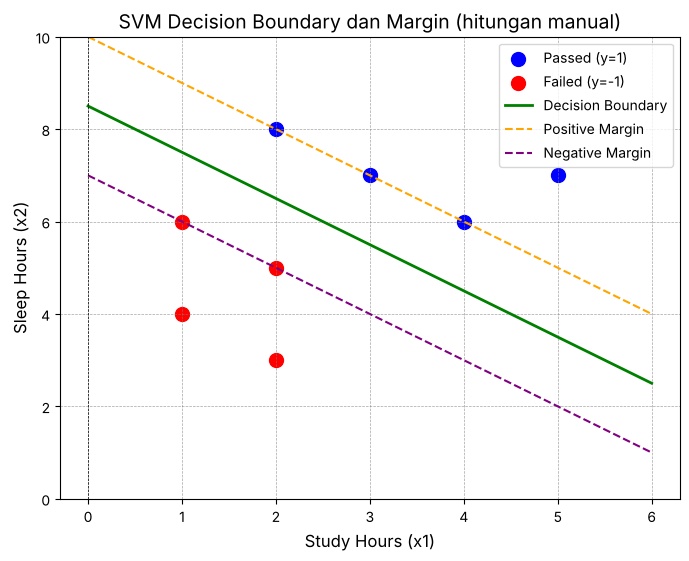

In [44]:
r = np.linspace(0, 6, 100)

batas_manual = -r + 8.5
margin_pos_manual = -r + 10    # hasil koreksi
margin_neg_manual = -r + 7     # hasil koreksi

# lebar margin = 2 / ||w||
w_manual = np.array([2/3, 2/3])
print("lebar margin manual:", round(2 / np.linalg.norm(w_manual), 4))

plt.figure(figsize=(8, 6))
plt.scatter(x1[y == 1], x2[y == 1], color='blue', label='Passed (y=1)', s=100)
plt.scatter(x1[y == -1], x2[y == -1], color='red', label='Failed (y=-1)', s=100)
plt.plot(r, batas_manual, color='green', label='Decision Boundary', linewidth=2)
plt.plot(r, margin_pos_manual, color='orange', linestyle='--', label='Positive Margin', linewidth=1.5)
plt.plot(r, margin_neg_manual, color='purple', linestyle='--', label='Negative Margin', linewidth=1.5)

plt.title('SVM Decision Boundary dan Margin (hitungan manual)', fontsize=14)
plt.xlabel('Study Hours (x1)', fontsize=12)
plt.ylabel('Sleep Hours (x2)', fontsize=12)
plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
plt.axvline(0, color='black', linewidth=0.5, linestyle='--')
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(fontsize=10)
plt.ylim(0, 10)
plt.show()

## Implementasi dengan sklearn

In [45]:
clf = svm.SVC(kernel='linear')
clf.fit(X, y)

w = clf.coef_[0]
b = clf.intercept_[0]

print("w1, w2 :", w.round(4))
print("b      :", round(b, 4))
print()
print("support vector hasil sklearn:")
print(clf.support_vectors_)
print("jumlah support vector tiap kelas (kelas -1, kelas +1):", clf.n_support_)

w1, w2 : [0.6667 0.6667]
b      : -5.6667

support vector hasil sklearn:
[[1. 6.]
 [2. 5.]
 [2. 8.]
 [3. 7.]
 [4. 6.]]
jumlah support vector tiap kelas (kelas -1, kelas +1): [2 3]


In [46]:
# bandingkan dengan hitungan manual
print("w sama dengan manual? ", np.allclose(w, [2/3, 2/3]))
print("b sama dengan manual? ", np.isclose(b, -17/3))
print()
print(f"persamaan garis batas dari sklearn: x2 = {-w[0]/w[1]:.2f} x1 + {-b/w[1]:.2f}")
print(f"margin positif: x2 = {-w[0]/w[1]:.2f} x1 + {(1 - b)/w[1]:.2f}")
print(f"margin negatif: x2 = {-w[0]/w[1]:.2f} x1 + {(-1 - b)/w[1]:.2f}")
print("lebar margin:", round(2 / np.linalg.norm(w), 4))

w sama dengan manual?  True
b sama dengan manual?  True

persamaan garis batas dari sklearn: x2 = -1.00 x1 + 8.50
margin positif: x2 = -1.00 x1 + 10.00
margin negatif: x2 = -1.00 x1 + 7.00
lebar margin: 2.1213


Hasilnya w = [0,667, 0,667] dan b = -5,667 (yang sama dengan -17/3), jadi sama persis dengan hitungan manual. Persamaan garis batas dan lebar margin (2,12) juga sama. Jadi teori dan praktik konsisten, hanya bagian margin di catatan yang perlu dikoreksi seperti dijelaskan sebelumnya.

## Visualisasi hasil sklearn

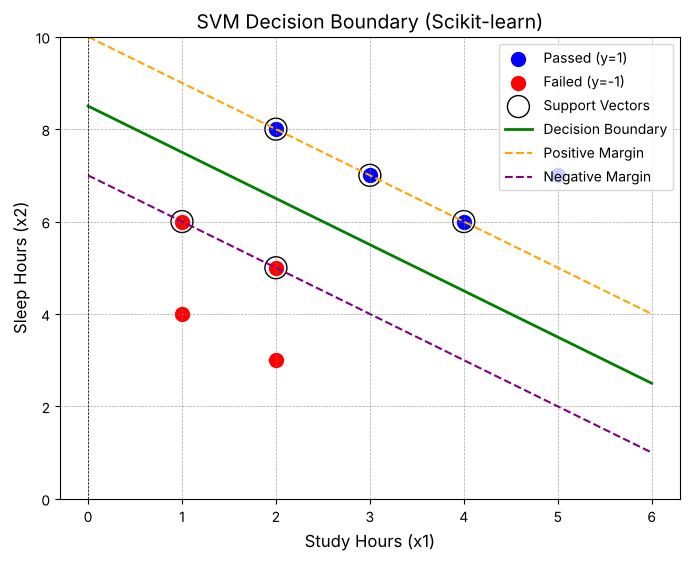

In [47]:
x1_range = np.linspace(0, 6, 100)
decision_boundary = -(w[0] * x1_range + b) / w[1]
margin_positive = -(w[0] * x1_range + b - 1) / w[1]
margin_negative = -(w[0] * x1_range + b + 1) / w[1]

plt.figure(figsize=(8, 6))
plt.scatter(x1[y == 1], x2[y == 1], color='blue', label='Passed (y=1)', s=100)
plt.scatter(x1[y == -1], x2[y == -1], color='red', label='Failed (y=-1)', s=100)

# lingkari support vector
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=250,
            facecolors='none', edgecolors='black', label='Support Vectors')

plt.plot(x1_range, decision_boundary, color='green', label='Decision Boundary', linewidth=2)
plt.plot(x1_range, margin_positive, color='orange', linestyle='--', label='Positive Margin', linewidth=1.5)
plt.plot(x1_range, margin_negative, color='purple', linestyle='--', label='Negative Margin', linewidth=1.5)

plt.title('SVM Decision Boundary (Scikit-learn)', fontsize=14)
plt.xlabel('Study Hours (x1)', fontsize=12)
plt.ylabel('Sleep Hours (x2)', fontsize=12)
plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
plt.axvline(0, color='black', linewidth=0.5, linestyle='--')
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(fontsize=10)
plt.ylim(0, 10)
plt.show()

Plot dari sklearn sama persis dengan plot hitungan manual (setelah margin dikoreksi). Selain itu, sklearn menemukan 5 support vector: (1,6), (2,5), (2,8), (3,7), dan (4,6). Di hitungan manual hanya dipilih 4 titik, padahal (2,8) juga jumlahnya 10 sehingga ikut berada di garis margin positif. Memasukkan titik itu tidak mengubah w maupun b.

## Tambahan: Prediksi data baru

Setelah model dilatih, bisa dipakai untuk memprediksi siswa baru. `decision_function` memberi nilai w·x + b: positif berarti prediksi lulus, negatif tidak lulus, dan nilainya menunjukkan seberapa jauh dari garis batas (jarak sebenarnya = nilai / ||w||).

In [48]:
siswa_baru = np.array([[3, 5], [4, 8], [1, 2], [4, 4.5]])

nilai = clf.decision_function(siswa_baru)
prediksi = clf.predict(siswa_baru)

hasil = pd.DataFrame(siswa_baru, columns=['belajar (x1)', 'tidur (x2)'])
hasil['w.x + b'] = nilai.round(3)
hasil['prediksi'] = np.where(prediksi == 1, 'lulus', 'tidak lulus')
hasil['jarak ke garis'] = (nilai / np.linalg.norm(w)).round(3)
hasil

,belajar (x1),tidur (x2),w.x + b,prediksi,jarak ke garis
0,3.0,5.0,-0.333,tidak lulus,-0.354
1,4.0,8.0,2.333,lulus,2.475
2,1.0,2.0,-3.667,tidak lulus,-3.889
3,4.0,4.5,-0.000,tidak lulus,-0.000


Hasilnya konsisten dengan aturan x1 + x2 di atas atau di bawah 8,5. Titik (3, 5) jumlahnya 8 jadi sedikit di bawah garis batas (tidak lulus), titik (4, 8) jumlahnya 12 jadi jauh di atas (lulus), dan titik (1, 2) jauh di bawah. Titik (4, 4.5) jumlahnya tepat 8,5 sehingga nilainya hampir 0 dan jaraknya ke garis hampir 0; itu titik yang paling ragu-ragu, jadi prediksinya di situ praktis ditentukan oleh pembulatan angka.

## Tambahan: Pengaruh parameter C

Data ini bisa dipisahkan sempurna oleh garis lurus, jadi kalau `C` besar hasilnya sama dengan hard margin. Kalau `C` dibuat sangat kecil, SVM lebih toleran terhadap titik yang masuk ke dalam margin (soft margin), sehingga margin makin lebar. Saya coba beberapa nilai C.

In [49]:
baris = []
for C in [0.01, 0.05, 0.1, 1, 100, 1000]:
    m = svm.SVC(kernel='linear', C=C).fit(X, y)
    baris.append([C, m.coef_[0][0].round(4), m.coef_[0][1].round(4),
                  m.intercept_[0].round(4), len(m.support_),
                  round(2 / np.linalg.norm(m.coef_[0]), 3),
                  m.score(X, y)])

pd.DataFrame(baris, columns=['C', 'w1', 'w2', 'b', 'jumlah SV', 'lebar margin', 'akurasi'])

,C,w1,w2,b,jumlah SV,lebar margin,akurasi
0,0.01,0.0800,0.1000,-0.7800,8,15.617,1.0
1,0.05,0.2560,0.3080,-2.4360,8,4.994,1.0
2,0.10,0.4000,0.4000,-3.0000,6,3.536,1.0
3,1.00,0.6667,0.6667,-5.6667,5,2.121,1.0
4,100.00,0.6667,0.6667,-5.6667,5,2.121,1.0
5,1000.00,0.6667,0.6667,-5.6667,5,2.121,1.0


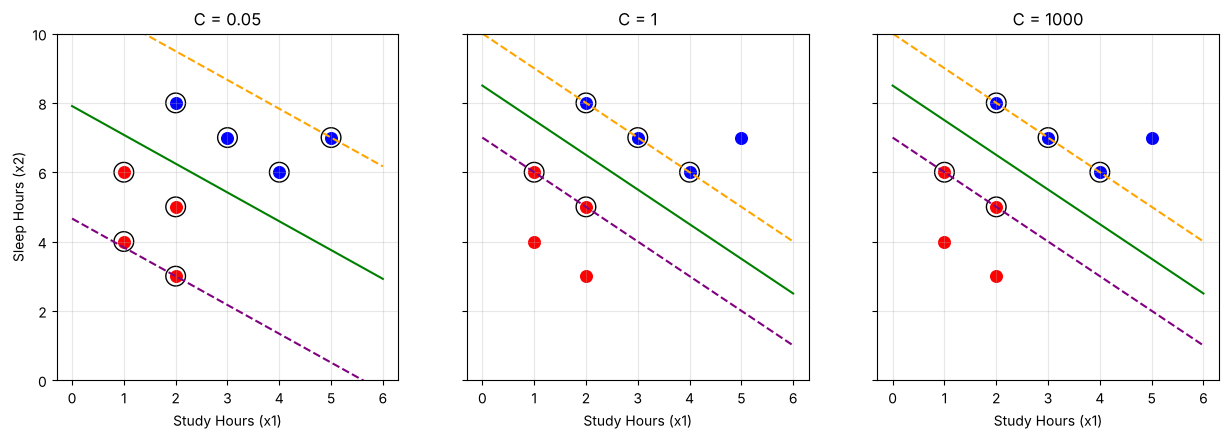

In [50]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for a, C in zip(ax, [0.05, 1, 1000]):
    m = svm.SVC(kernel='linear', C=C).fit(X, y)
    ww, bb = m.coef_[0], m.intercept_[0]
    a.scatter(x1[y == 1], x2[y == 1], color='blue', s=70)
    a.scatter(x1[y == -1], x2[y == -1], color='red', s=70)
    a.scatter(m.support_vectors_[:, 0], m.support_vectors_[:, 1], s=200,
              facecolors='none', edgecolors='black')
    a.plot(x1_range, -(ww[0] * x1_range + bb) / ww[1], color='green')
    a.plot(x1_range, -(ww[0] * x1_range + bb - 1) / ww[1], 'orange', linestyle='--')
    a.plot(x1_range, -(ww[0] * x1_range + bb + 1) / ww[1], 'purple', linestyle='--')
    a.set_title(f'C = {C}')
    a.set_xlabel('Study Hours (x1)')
    a.set_ylim(0, 10)
    a.grid(alpha=0.3)
ax[0].set_ylabel('Sleep Hours (x2)')
plt.show()

Untuk C = 1 sampai 1000 hasilnya identik (w, b, 5 support vector, lebar margin 2,12) karena datanya bisa dipisahkan sempurna oleh garis lurus. Begitu C dikecilkan menjadi 0,1, 0,05, dan 0,01, margin makin lebar (3,5, lalu 5, lalu 15,6), support vector bertambah sampai akhirnya semua 8 titik menjadi support vector, dan garisnya ikut bergeser. Akurasi data latih tetap 100% di semua nilai C.

Jadi C kecil membuat model lebih toleran terhadap titik yang masuk margin (soft margin, lebih sederhana), sedangkan C besar membuat model ketat terhadap kesalahan (mendekati hard margin). Untuk data yang tidak terpisah sempurna, pengaturan C ini penting untuk menyeimbangkan antara overfitting dan underfitting.

## Tambahan: Membuktikan w dari dual_coef_

Di SVM, vektor bobot w sebenarnya dibangun dari support vector: w = jumlah dari (alpha_i · y_i · x_i). Di sklearn nilai alpha_i · y_i disimpan di `dual_coef_`. Saya cek apakah rumus ini menghasilkan w yang sama dengan `coef_`, dan apakah titik-titik non support vector memang berada di luar margin.

In [51]:
alpha_y = clf.dual_coef_[0]
sv = clf.support_vectors_

w_rekonstruksi = alpha_y @ sv
print("alpha_i * y_i :", alpha_y.round(4))
print("w dari rumus  :", w_rekonstruksi.round(4))
print("w dari coef_  :", clf.coef_[0].round(4))
print("sama?         :", np.allclose(w_rekonstruksi, clf.coef_[0]))
print()

# nilai w.x + b semua titik; support vector harus tepat di +1 atau -1
nilai_semua = clf.decision_function(X)
tabel_titik = pd.DataFrame({'x1': x1, 'x2': x2, 'y': y, 'w.x + b': nilai_semua.round(3)})
tabel_titik['support vector'] = np.isin(np.arange(len(X)), clf.support_)
tabel_titik

alpha_i * y_i : [-0.1812 -0.2632  0.1094  0.1846  0.1504]
w dari rumus  : [0.6667 0.6667]
w dari coef_  : [0.6667 0.6667]
sama?         : True



,x1,x2,y,w.x + b,support vector
0,2,8,1,1.000,True
1,1,6,-1,-1.000,True
2,3,7,1,1.000,True
3,1,4,-1,-2.333,False
4,4,6,1,1.000,True
5,2,5,-1,-1.000,True
6,5,7,1,2.333,False
7,2,3,-1,-2.333,False


Rumus w = jumlah (alpha_i · y_i · x_i) menghasilkan w yang sama persis dengan `coef_`, jadi w memang hanya ditentukan oleh 5 support vector. Dari tabel, kelima support vector bernilai tepat +1 atau -1. Tiga titik lainnya, yaitu (1,4), (5,7), dan (2,3), bernilai di luar margin (±2,333) dan bukan support vector, artinya kalau titik-titik itu dihapus, garis batasnya tidak berubah.

## Tambahan: Kalau ada data pencilan (soft margin)

Data aslinya bisa dipisahkan sempurna, jadi pengaruh C tidak terlalu terlihat. Saya tambahkan satu siswa pencilan: belajar 4 jam, tidur 3 jam, tapi lulus (+1). Titik ini berada di wilayah siswa yang tidak lulus, jadi akan menarik garis ke arahnya. Lalu saya lihat bagaimana C mengubah garis, margin, dan jumlah titik yang salah diklasifikasikan.

In [52]:
X_pencilan = np.vstack([X, [4, 3]])
y_pencilan = np.append(y, 1)

baris = []
model_pencilan = {}
for C in [0.1, 1, 10, 1000]:
    m = svm.SVC(kernel='linear', C=C).fit(X_pencilan, y_pencilan)
    model_pencilan[C] = m
    salah = int((m.predict(X_pencilan) != y_pencilan).sum())
    baris.append([C, m.coef_[0][0].round(3), m.coef_[0][1].round(3), m.intercept_[0].round(3),
                  len(m.support_), round(2 / np.linalg.norm(m.coef_[0]), 3), salah])

pd.DataFrame(baris, columns=['C', 'w1', 'w2', 'b', 'jumlah SV', 'lebar margin', 'titik salah'])

,C,w1,w2,b,jumlah SV,lebar margin,titik salah
0,0.1,0.400,0.400,-3.000,6,3.536,1
1,1.0,1.111,0.444,-4.777,4,1.672,0
2,10.0,1.666,0.667,-7.666,3,1.114,0
3,1000.0,1.666,0.667,-7.666,3,1.114,0


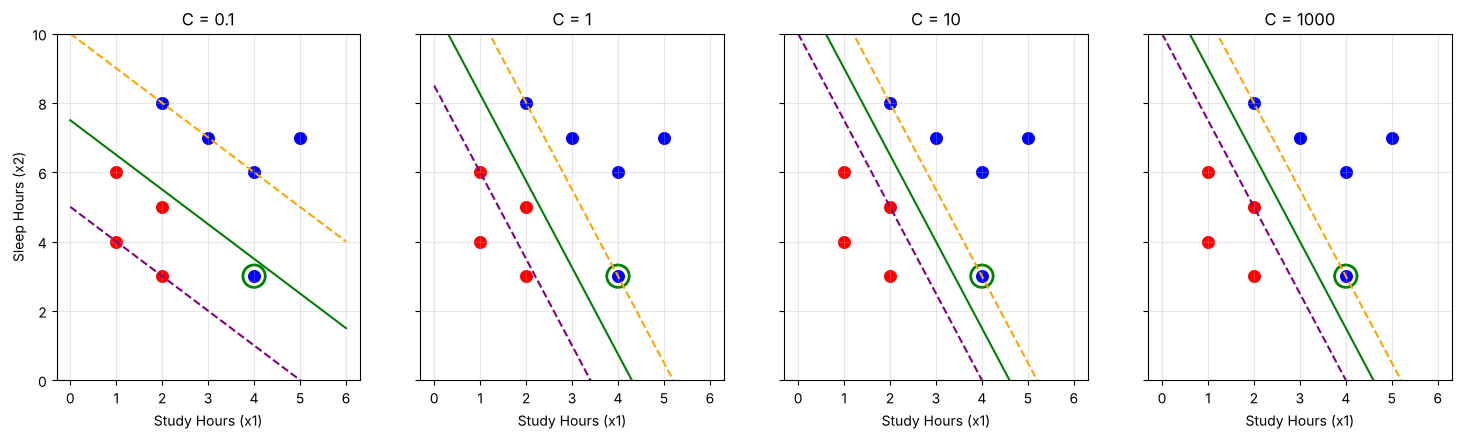

In [53]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for a, C in zip(ax, model_pencilan):
    m = model_pencilan[C]
    ww, bb = m.coef_[0], m.intercept_[0]
    a.scatter(X_pencilan[y_pencilan == 1][:, 0], X_pencilan[y_pencilan == 1][:, 1], color='blue', s=70)
    a.scatter(X_pencilan[y_pencilan == -1][:, 0], X_pencilan[y_pencilan == -1][:, 1], color='red', s=70)
    a.scatter(4, 3, s=260, facecolors='none', edgecolors='green', linewidths=2)   # pencilan
    a.plot(x1_range, -(ww[0] * x1_range + bb) / ww[1], color='green')
    a.plot(x1_range, -(ww[0] * x1_range + bb - 1) / ww[1], 'orange', linestyle='--')
    a.plot(x1_range, -(ww[0] * x1_range + bb + 1) / ww[1], 'purple', linestyle='--')
    a.set_title(f'C = {C}')
    a.set_xlabel('Study Hours (x1)')
    a.set_ylim(0, 10)
    a.grid(alpha=0.3)
ax[0].set_ylabel('Sleep Hours (x2)')
plt.show()

Titik pencilan ini ternyata masih bisa dipisahkan dengan garis lurus kalau C cukup besar (C=1 ke atas: 0 titik salah), tapi harganya garis berputar (w1 naik jadi sekitar 1,67 dan w2 sekitar 0,67), support vector berkurang jadi 3, dan margin menyempit dari 2,12 jadi 1,11. Jadi satu titik saja bisa menggeser model cukup jauh kalau modelnya ketat (C besar).

Dengan C=0,1 (lebih toleran) model memilih mengabaikan pencilan itu (1 titik salah), dan garisnya persis sama dengan hasil C=0,1 pada data tanpa pencilan (w=0,4 dan b=-3). Ini contoh trade-off soft margin: C kecil lebih tahan pencilan, C besar lebih setia ke data latih dan lebih mudah overfitting.

## Kesimpulan Latihan SVM (Kernel Linear)

- Hitungan manual menghasilkan w1 = w2 = 2/3, b = -17/3, dan garis batas x2 = -x1 + 8,5. Hasil `SVC(kernel='linear')` dari sklearn sama persis, termasuk saat w dihitung ulang dari `dual_coef_` dan support vector.
- Garis margin yang benar adalah x2 = -x1 + 10 dan x2 = -x1 + 7 (lebar margin sekitar 2,12), bukan +9 dan +8 seperti di catatan. Ini terbukti dari keempat support vector yang tepat berada di garis tersebut.
- sklearn menemukan 5 support vector, satu lebih banyak dari pilihan manual, yaitu titik (2,8) yang juga berada di garis margin. Titik lain tidak memengaruhi garis.
- Parameter C mengatur lebar margin: untuk data yang terpisah sempurna, C besar menghasilkan hard margin, sedangkan C sangat kecil membuat margin melebar dan support vector bertambah. Saat ada pencilan, C besar membuat garis bergeser mengikuti pencilan, sedangkan C kecil cenderung mengabaikannya.

# Kesimpulan Umum

Dari tiga latihan ini saya belajar bahwa:

1. SVM bisa dipakai untuk klasifikasi (SVC) maupun regresi (SVR), dan keduanya sama-sama sensitif terhadap skala data dan pengaturan parameter (C, gamma, kernel). Hasil default belum tentu bagus, seperti pada latihan SVR, yang ternyata bermasalah karena skala target tidak cocok dengan nilai C.
2. Akurasi saja tidak cukup untuk menilai model, terutama pada data tidak seimbang seperti dataset diabetes. Perlu dibandingkan dengan baseline dan dilihat juga precision, recall, confusion matrix, dan ROC AUC.
3. Hasil dari satu kali pembagian data bisa menipu, apalagi untuk data kecil seperti Salary_Data (30 baris). Cross validation berulang memberi gambaran yang lebih jujur.
4. Kernel yang lebih kompleks tidak selalu lebih baik. Di latihan SVM klasifikasi dan SVR, model yang hampir linear (kernel linear, Logistic Regression, Linear Regression) sudah sama bagusnya, dan di latihan SVM kernel linear, hitungan manual sudah cukup untuk memahami konsep margin dan support vector.
5. Preprocessing (standarisasi, imputasi) lebih baik dimasukkan ke dalam pipeline supaya tidak ada data leakage.

## Daftar Referensi

1. Materi "Latihan SKLearn SVM untuk Klasifikasi" (dataset Pima Indian Diabetes).
2. Materi "Latihan SKLearn SVR" (dataset Salary_Data).
3. Materi "Latihan SVM" (perhitungan manual SVM kernel linear dan implementasi SKLearn).
4. Dokumentasi Scikit-learn, Support Vector Machines: https://scikit-learn.org/stable/modules/svm.html
5. Dokumentasi Scikit-learn, Tuning hyper-parameters (GridSearchCV): https://scikit-learn.org/stable/modules/grid_search.html